## Exercise 2

For this exercise , you will be working with the [Titanic Data Set from Kaggle](https://www.kaggle.com/c/titanic). This is a very famous data set and very often is a student's first step in Data Analytics! 

The Dataset has been given to you on D2L. You need to download the .csv file from your assignment folder. The above link is just for a reference story about the data. 


1- For this assignment, you need to perform explorotary data analysis and answer at least three hypotheses based on the dataset. You may need to use your knowledge of statiscts to analyze this data.

Here are three possible hypotheses that you can define for this dataset (you can define your own hypotheses as well):

- Determine if the survival rate is associated to the class of passenger
- Determine if the survival rate is associated to the gender
- Determine the survival rate is associated to the age


2- For each hypothesis, you need to make at least one plot. 

3- Write a summary of your findings in one page (e.g., summary statistics, plots) and submit the pdf file. Therefore, for part 2 of your assignment, you need to submit one jupyter notebook file and one pdf file.

This will be your first end to end data analysis project. For this assignment, you will be graded on you overall analysis, and your final report.

4- Push your code and project to github and provide the link to your code here.


https://github.com/Karlacristheljp/Titanic---Exploratory-Data-Analysis-EDA-

Ensure that your github project is organized to at least couple of main folders, ensure that you have the README file as well:

Src
Data
Docs
Results
Read this link for further info: https://gist.github.com/ericmjl/27e50331f24db3e8f957d1fe7bbbe510

In [146]:
# Import galleries
import os
import pandas as pd #library to manipulate data
import matplotlib.pyplot as plt #library for graphics
import seaborn as sns
import numpy as nd
import matplotlib.ticker as mtick
# 2. Configurar el estilo visual de los gráficos
sns.set_theme(style="whitegrid")

# Read the dataset
# Como nuestro notebook está en 'Src', subimos un nivel ('..') y entramos a 'Data'
ruta_titanic = os.path.join("..", "Data", "train.csv") 
#os.path.join("..", "Data", "train.csv") we use this to create a path, I said to python jump out of "Scr" and go in to data and search
#read the document .cvs
df_titanic = pd.read_csv(ruta_titanic)



Variable Notes
pclass: A proxy for socio-economic status (SES)
1st = Upper
2nd = Middle
3rd = Lower

age: Age is fractional if less than 1. If the age is estimated, is it in the form of xx.5

sibsp: The dataset defines family relations in this way...
Sibling = brother, sister, stepbrother, stepsister
Spouse = husband, wife (mistresses and fiancés were ignored)

parch: The dataset defines family relations in this way...
Parent = mother, father
Child = daughter, son, stepdaughter, stepson
Some children travelled only with a nanny, therefore parch=0 for them.

embarked	Port of Embarkation	C = Cherbourg, Q = Queenstown, S = Southampton

## 1. Structure and dimension ##

#### 1.1 Dataframe dimension and preview

In [4]:
df_titanic.shape

(891, 12)

In [5]:
df_titanic.head(7)

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S
5,6,0,3,"Moran, Mr. James",male,NaN,0,0,330877,8.4583,NaN,Q
6,7,0,1,"McCarthy, Mr. Timothy J",male,54.0,0,0,17463,51.8625,E46,S


#### 1.2 General information and data types

In [7]:
df_titanic.info()

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 118.9 KB


**Statistical summary**

In [31]:
print("Statistical summary")
df_titanic.describe().T[["count", "mean", "std", "min", "50%", "max"]].head(10)

Statistical summary


,count,mean,std,min,50%,max
PassengerId,891.0,446.000000,257.353842,1.00,446.0000,891.0000
Survived,891.0,0.383838,0.486592,0.00,0.0000,1.0000
Pclass,891.0,2.308642,0.836071,1.00,3.0000,3.0000
Age,714.0,29.699118,14.526497,0.42,28.0000,80.0000
SibSp,891.0,0.523008,1.102743,0.00,0.0000,8.0000
Parch,891.0,0.381594,0.806057,0.00,0.0000,6.0000
Fare,891.0,32.204208,49.693429,0.00,14.4542,512.3292


In [158]:
df_titanic.columns

Index(['PassengerId', 'Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp',
       'Parch', 'Ticket', 'Fare', 'Cabin', 'Embarked'],
      dtype='str')

**Percentage of Survived**

In [39]:
df_titanic= df_titanic["Survived"].value_counts(normalize=True) * 100
df_titanic

Survived
0    61.616162
1    38.383838
Name: proportion, dtype: float64

## 2. Missing Values Analysis

#### 2.1 Quantification of Null Data

In [42]:
missing_data = df_titanic.isnull().sum()
missing_data = missing_data[ missing_data > 0].sort_values(ascending = False)
print ("Columns with missing values:")
print (missing_data.head(10))

Columns with missing values:
Cabin       687
Age         177
Embarked      2
dtype: int64


## Exploratory Data Analysis (EDA)

### 3. Bivariate & Multivariate Analysis (Hypotheses Testing)

**3.1 Hypothesis #1 Determine if the survival rate is associated to the class of passenger**

In [118]:
#groupby function groups the passenger first by "Class" and then by "sex" [As a list]
# Then after filtering, I am interested in only the values in ["Survived"] column and calculate the mean()
# .reset_index() for table with a clean structure
df_titanic_by_class= df_titanic.groupby(["Pclass","Sex"])["Survived"].mean()*100
df_titanic_by_class.reset_index()

,Pclass,Sex,Survived
0,1,female,96.808511
1,1,male,36.885246
2,2,female,92.105263
3,2,male,15.740741
4,3,female,50.000000
5,3,male,13.544669


In [113]:
df_titanic_by_class= df_titanic.groupby(["Pclass","Sex"])["Survived"].value_counts(normalize=True)*100
df_titanic_by_class.reset_index()

,Pclass,Sex,Survived,proportion
0,1,female,1,96.808511
1,1,female,0,3.191489
2,1,male,0,63.114754
3,1,male,1,36.885246
4,2,female,1,92.105263
5,2,female,0,7.894737
6,2,male,0,84.259259
7,2,male,1,15.740741
8,3,female,1,50.000000
9,3,female,0,50.000000


**Bar graph of Survival rate by Passenger Class**

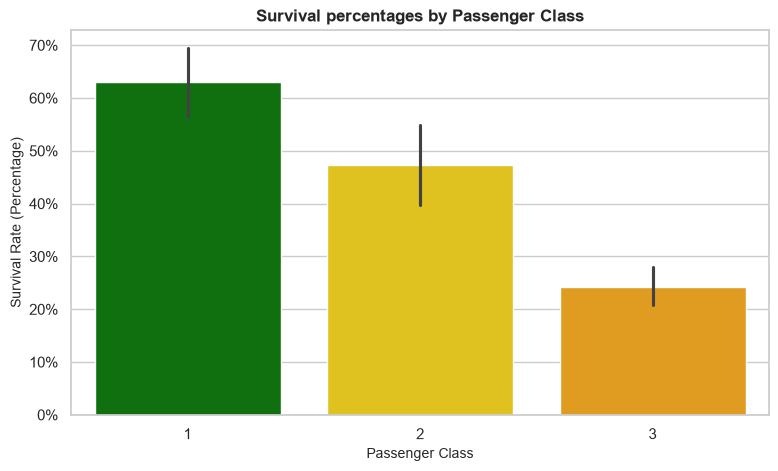

In [136]:

#Set up size for the plot
custome_palette= ["green" , "gold", "orange"]

plt.figure(figsize=(9, 5))

ax= sns.barplot(x= "Pclass", y= "Survived", hue="Pclass", data= df_titanic, palette=custome_palette, legend=False)

ax.yaxis.set_major_formatter(mtick.PercentFormatter(xmax=1.0))
plt.title("Survival percentages by Passenger Class", fontsize= 12, fontweight='bold')
plt.xlabel("Passenger Class", fontsize= 10)
plt.ylabel("Survival Rate (Percentage)", fontsize= 10)

# Save the generated plot into the Results folder 
plt.savefig('../Results/hypothesis_class_survival_percentage.png', bbox_inches='tight')
plt.show()

**Bar graph of Survival rate by Passenger Class and Sex**

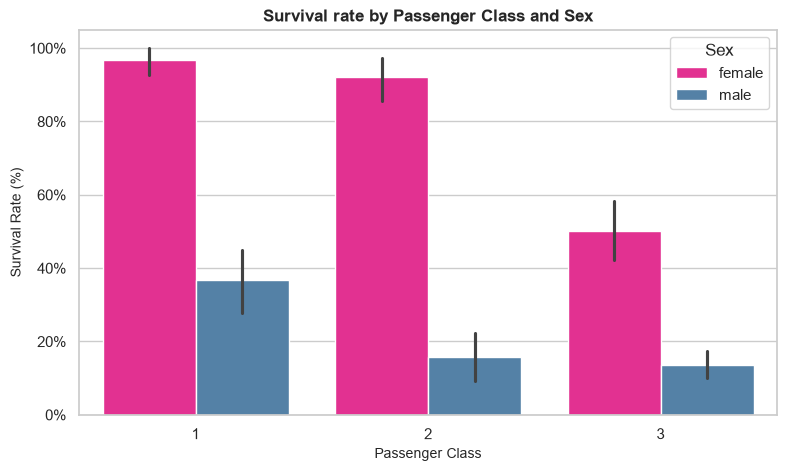

In [152]:
#Set up size for the plot
custome_palette= ["deeppink" , "steelblue"]
plt.figure(figsize=(9, 5))


ax=sns.barplot(x= "Pclass", y= "Survived", hue= "Sex", data= df_titanic, palette= custome_palette)

ax.yaxis.set_major_formatter(mtick.PercentFormatter(xmax=1.0))
plt.title("Survival rate by Passenger Class and Sex", fontsize= 12, fontweight='bold')
plt.xlabel("Passenger Class", fontsize= 10)
plt.ylabel("Survival Rate (%)", fontsize= 10)

# Save the generated plot into the Results folder 
plt.savefig('../Results/hypothesis_class_survival_and sex.png', bbox_inches='tight')
plt.show()

**Percentage of survival rates**

In [119]:
df_titanic_by_class= df_titanic.groupby("Pclass")["Survived"].mean()*100
df_titanic_by_class.reset_index()

,Pclass,Survived
0,1,62.962963
1,2,47.282609
2,3,24.236253


**3.2 Hypothesis #2 - Determine if the survival rate is associated to the gender**

In [52]:
df_titanic_by_class= df_titanic.groupby("Sex")["Survived"].mean().reset_index()
df_titanic_by_class

,Sex,Survived
0,female,0.742038
1,male,0.188908


**Bar plot of Survival rate by Sex**

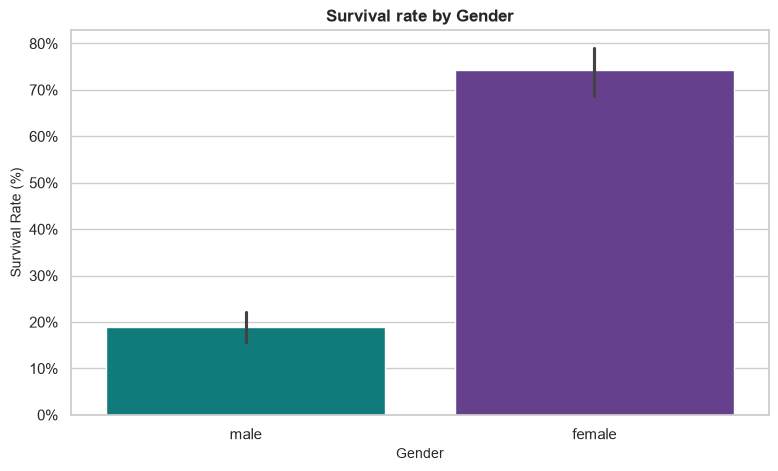

In [151]:
#Set up size for the plot
custome_palette= ["darkcyan" , "rebeccapurple"]
plt.figure(figsize=(9, 5))


ax= sns.barplot(x= "Sex", y= "Survived", hue="Sex", legend=False, data= df_titanic, palette= custome_palette)

ax.yaxis.set_major_formatter(mtick.PercentFormatter(xmax=1.0))
plt.title("Survival rate by Gender", fontsize= 12, fontweight='bold')
plt.xlabel("Gender", fontsize= 10)
plt.ylabel("Survival Rate (%)", fontsize= 10)

# Save the generated plot into the Results folder 
plt.savefig('../Results/hypothesis_survival_rates_by_gender.png', bbox_inches='tight')
plt.show()

**3.3 Hypothesis #3 Determine the survival rate is associated to the age**

Mean of group by Age

In [53]:
df_titanic_by_class= df_titanic.groupby("Age")["Survived"].mean().reset_index()
df_titanic_by_class

,Age,Survived
0,0.42,1.0
1,0.67,1.0
2,0.75,1.0
3,0.83,1.0
4,0.92,1.0
...,...,...
83,70.00,0.0
84,70.50,0.0
85,71.00,0.0
86,74.00,0.0


**Histograms of Age Distribution Density by Survival Status**

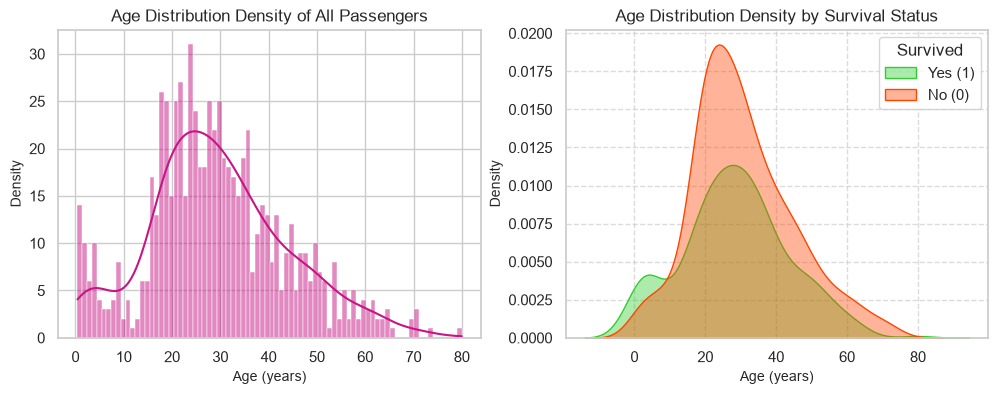

In [156]:
custome_palette= ["orangered","limegreen"]
fig, axes = plt.subplots(1, 2, figsize=(12, 4))


sns.histplot(df_titanic['Age'], kde=True, color='mediumvioletred', bins=80, ax=axes[0])
axes[0].set_title("Age Distribution Density of All Passengers", fontsize=12)
axes[0].set_xlabel('Age (years)', fontsize=10)
axes[0].set_ylabel('Density', fontsize=10)


sns.kdeplot(data= df_titanic, x='Age', hue="Survived", fill=True, palette=custome_palette ,alpha=0.4, ax=axes[1])
axes[1].set_title("Age Distribution Density by Survival Status", fontsize=12)
axes[1].set_xlabel('Age (years)', fontsize=10)
axes[1].set_ylabel('Density', fontsize=10)

plt.legend(title='Survived', labels=['Yes (1)', 'No (0)'], loc='upper right')
plt.grid(axis='both', linestyle='--', alpha=0.7)

plt.savefig('../Results/Age_Distribution_Density.png', bbox_inches='tight')
plt.show()

**Histogram of Age and Survival Count (with KDE)**

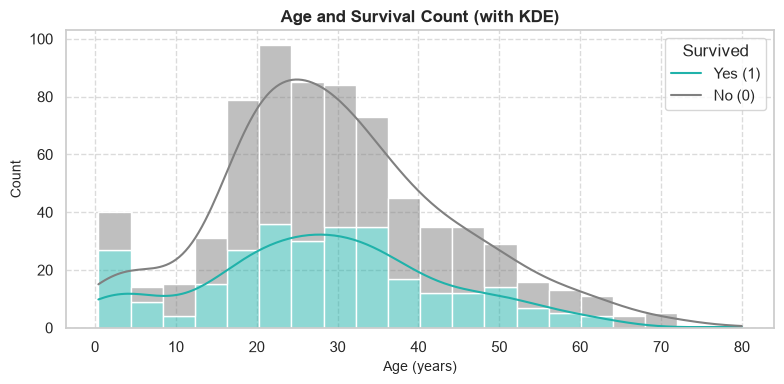

In [102]:
custome_palette= ["grey","lightseagreen"]
plt.figure(figsize=(8, 4))
sns.histplot(
    data=df_titanic, 
    x='Age', 
    hue='Survived', 
    multiple='stack', 
    palette=custome_palette, 
    kde=True, 
)
plt.title("Age and Survival Count (with KDE)", fontsize=12, fontweight='bold')
plt.xlabel('Age (years)', fontsize=10)
plt.ylabel('Count', fontsize=10)

plt.legend(title='Survived', labels=['Yes (1)', 'No (0)'], loc='upper right')
plt.grid(axis='both', linestyle='--', alpha=0.7)

plt.tight_layout()
plt.savefig('../Results/hypothesis_age_survival.png', bbox_inches='tight')
plt.show()


**3.4 Correlation Matrix of Titanic Numerical Variables**

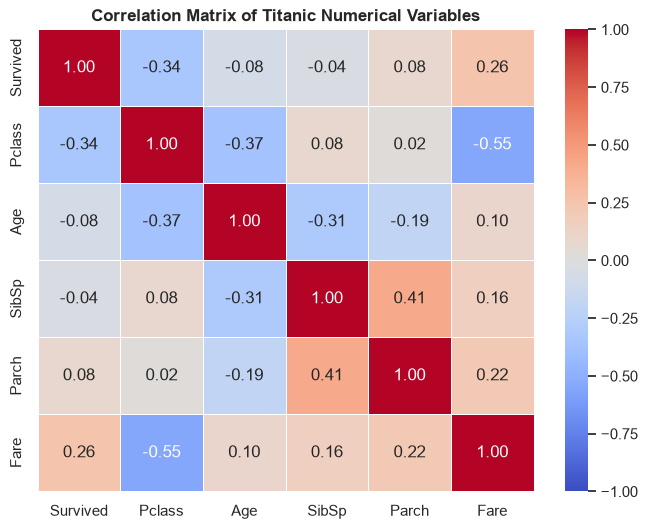

In [95]:
# Select only the numerical columns 
numerical_cols = ['Survived', 'Pclass', 'Age', 'SibSp', 'Parch', 'Fare']
correlation_matrix = df_titanic[numerical_cols].corr()


plt.figure(figsize=(8, 6))
sns.heatmap(
    correlation_matrix, 
    annot=True, 
    cmap='coolwarm', 
    fmt='.2f', 
    linewidths=0.5, 
    vmin=-1, 
    vmax=1
)

plt.title('Correlation Matrix of Titanic Numerical Variables', fontsize=12, fontweight='bold')

plt.savefig('../Results/correlation_matrix.png', bbox_inches='tight')

plt.show()